In [2]:
from numpy import pi

In [3]:
%matplotlib inline

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_distribution
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit_ibm_runtime import SamplerV2
import matplotlib.pyplot as plt

In [4]:
import mthree

In [ ]:
MiToken = "##"
MiInstance = "##"
Channel = "ibm_cloud"

In [6]:
# Conexión al servicio IBM Quantum
service = QiskitRuntimeService(
    channel=Channel,
    token=MiToken,
    instance=MiInstance
)

# Selección de un procesador cuántico real
IBMQProcessor = service.least_busy(
    operational=True,
    simulator=False,
    min_num_qubits=3
)

print("Procesador seleccionado:", IBMQProcessor.name)
print("Número de qubits:", IBMQProcessor.num_qubits)

qiskit_runtime_service._discover_account:WARNING:2026-10-14 01:42:40,781: Loading account with the given token. A saved account will not be used.


Procesador seleccionado: ibm_fez
Número de qubits: 156


# Circuit for a GHZ State:

In [7]:
nqubits = 3
circuit = QuantumCircuit(nqubits, nqubits)
circuit.h(0)
circuit.cx(0,1)
circuit.cx(1,2)
circuit.measure([0,1,2], [0,1,2])

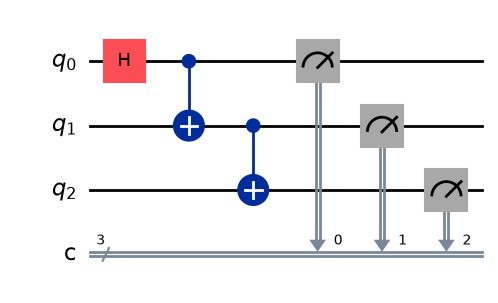

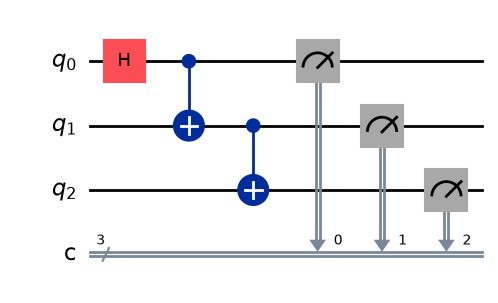

In [8]:
circuit.draw(output='mpl')

In [9]:
pm = generate_preset_pass_manager(
    optimization_level=1,
    backend=IBMQProcessor
)

sampler = SamplerV2(mode=IBMQProcessor)

shots = 5000

/tmp/ipykernel_29835/727905633.py:6: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=IBMQProcessor)


In [10]:
transpiled_circuit = pm.run(circuit)

In [11]:
# Define the number of shots for the execution. 
shotno=1024

# Run the circuit on a real quantum computer. NB! This may take a while.
job = sampler.run([transpiled_circuit], shots= 5000)

# ID del Job para rastrear la ejecución del circuito en tiempo real.
print(f">>> Job ID: {job.job_id()}")

# Consulta del estado de la ejecución del circuito cuántico
print(f">>> Job Status: {job.status()}")

>>> Job ID: db7dsparaffc73fab8gg
>>> Job Status: QUEUED


In [12]:
device_result = job.result()

# Get results for the first (and only) PUB
pub_result = device_result[0]

# Get count measurement results
device_counts = pub_result.data.c.get_counts()

print(
    f"Counts for the 'meas' output register: {device_counts}"
)

Counts for the 'meas' output register: {'111': 2212, '000': 2390, '100': 19, '110': 186, '001': 100, '101': 38, '010': 41, '011': 14}


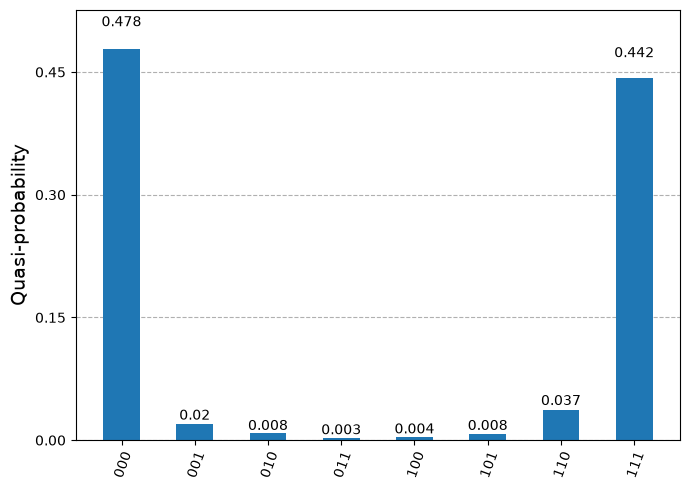

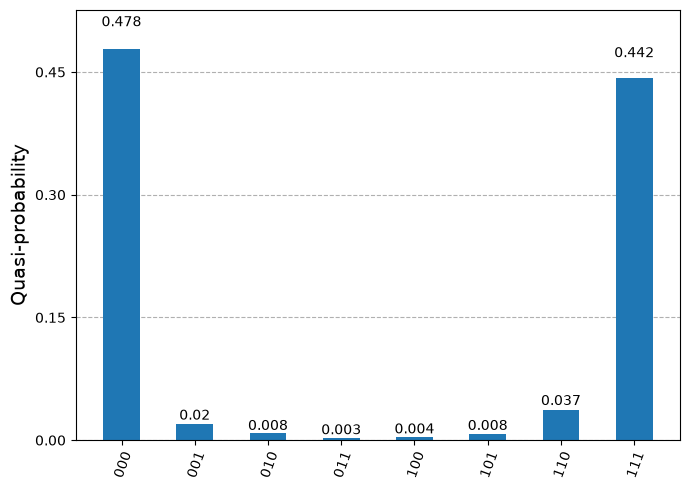

In [13]:
# Probabilidades de medición de cada salida, dada la ejecución real realizada.
plot_distribution(device_counts)

In [14]:
mit = mthree.M3Mitigation(IBMQProcessor)
mit.cals_from_system(range(circuit.num_qubits))

mitigate_quasi = mit.apply_correction(device_counts, range(circuit.num_qubits))
mitigate_probs = mitigate_quasi.nearest_probability_distribution()

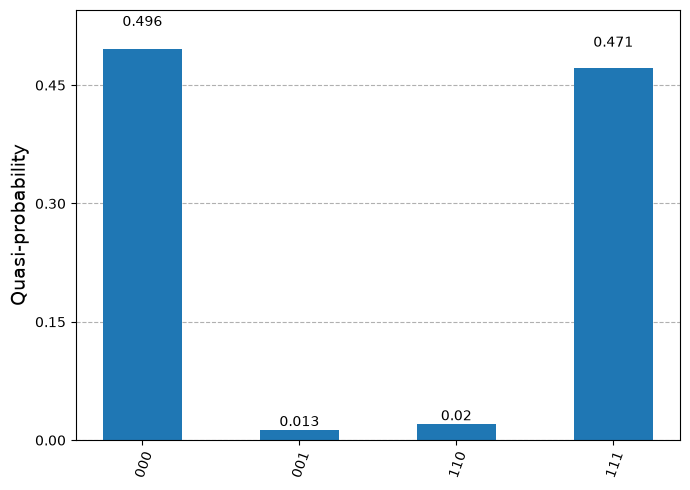

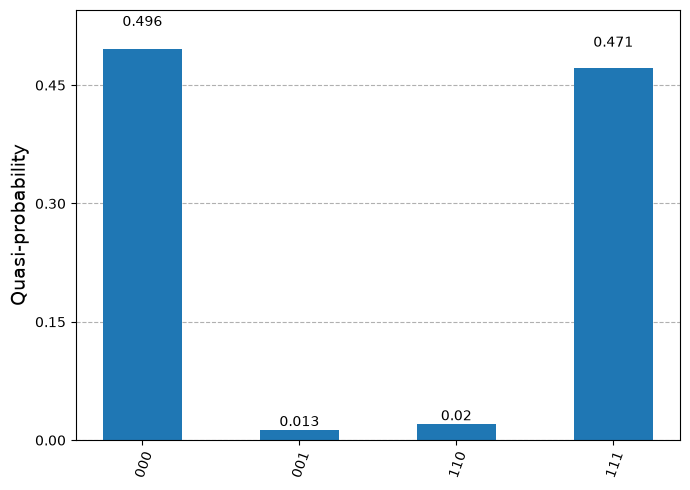

In [15]:
plot_distribution(mitigate_probs)

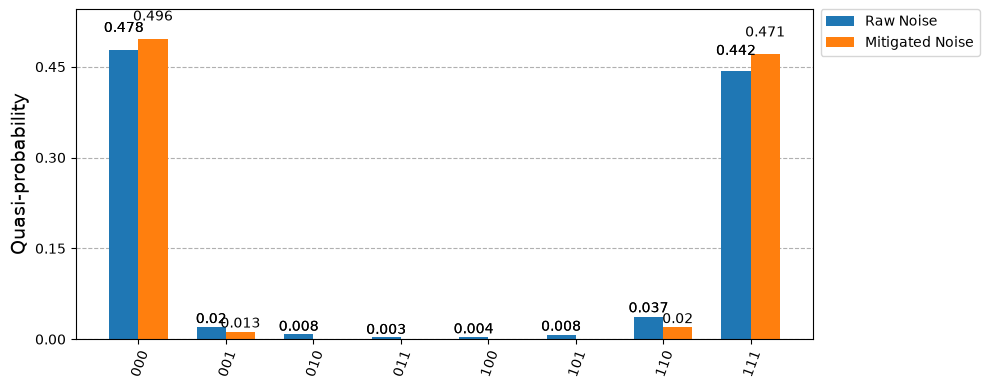

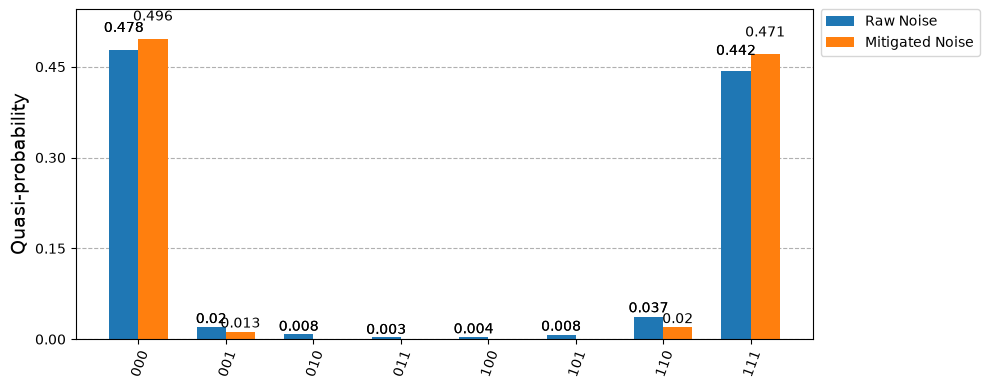

In [16]:
plot_distribution([device_counts, mitigate_probs], figsize=(10,4), legend=['Raw Noise', 'Mitigated Noise'])

# Circuit for a W State:

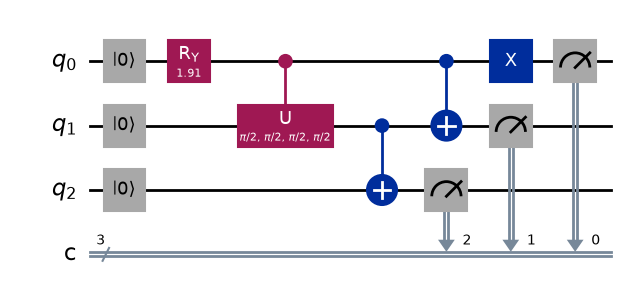

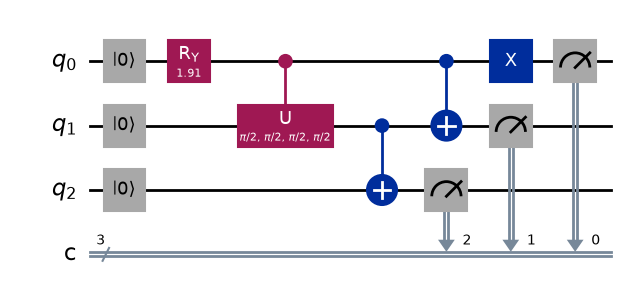

In [17]:
qreg_q = QuantumRegister(3, 'q')
creg_c = ClassicalRegister(3, 'c')
circuit2 = QuantumCircuit(qreg_q, creg_c)

circuit2.reset(qreg_q[0])
circuit2.reset(qreg_q[1])
circuit2.reset(qreg_q[2])
circuit2.ry(1.9106332362490184, qreg_q[0])
circuit2.cu(pi / 2, pi / 2, pi / 2, pi / 2, qreg_q[0], qreg_q[1])
circuit2.cx(qreg_q[1], qreg_q[2])
circuit2.cx(qreg_q[0], qreg_q[1])
circuit2.x(qreg_q[0])
circuit2.measure(qreg_q[0], creg_c[0])
circuit2.measure(qreg_q[1], creg_c[1])
circuit2.measure(qreg_q[2], creg_c[2])

circuit2.draw(output='mpl')

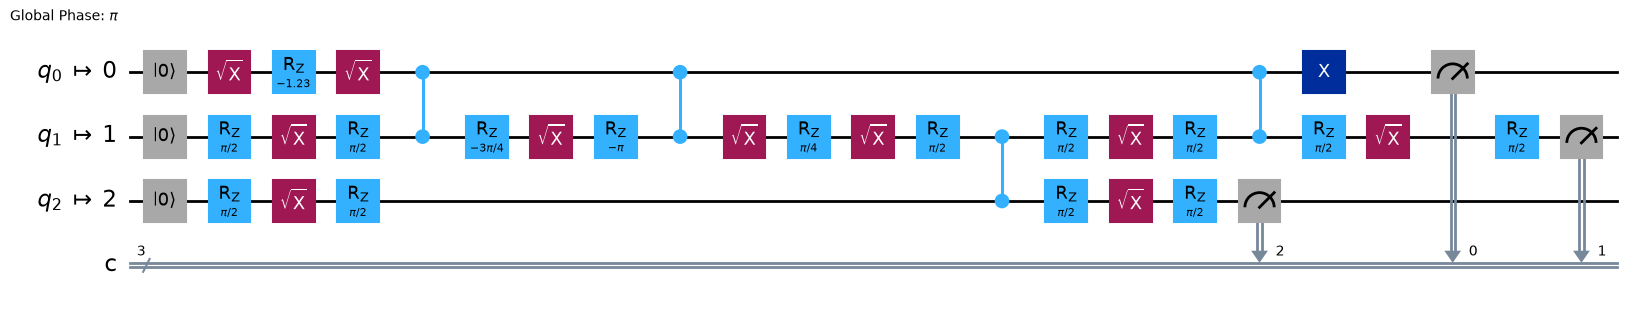

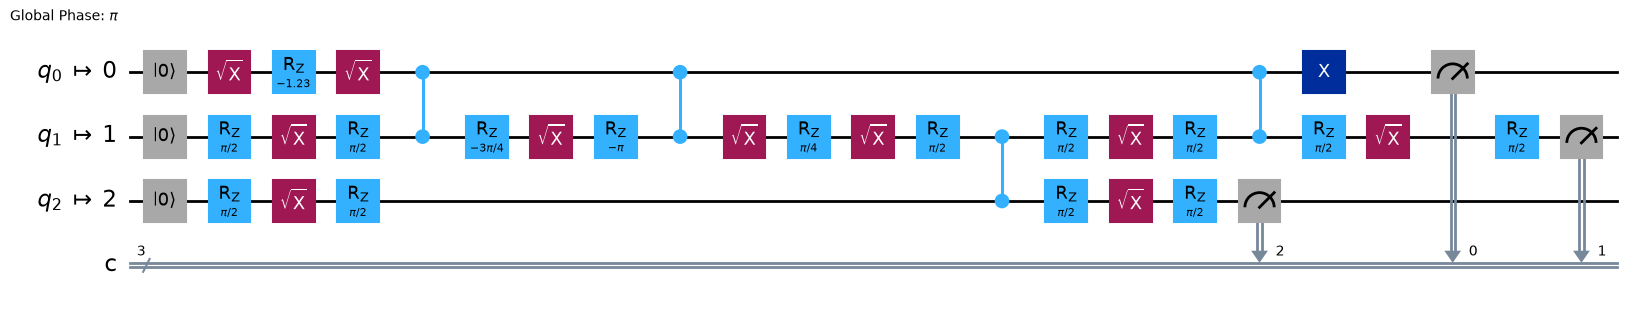

In [18]:
# Adaptar el circuito W al procesador cuántico real
transpiled_circuit2 = pm.run(circuit2)

# Visualizar el circuito adaptado
transpiled_circuit2.draw(output="mpl", idle_wires=False)

In [19]:
o = 1024

# Ejecutar el circuito W en el computador cuántico real
job2 = sampler.run([transpiled_circuit2], shots=shotno)

# ID del Job para rastrear la ejecución
print(f">>> Job ID: {job2.job_id()}")

# Consultar el estado de la ejecución
print(f">>> Job Status: {job2.status()}")

>>> Job ID: db7dtfmil99s73fnth20
>>> Job Status: RUNNING


Counts for the 'meas' output register: {'100': 356, '001': 337, '010': 249, '000': 24, '011': 11, '111': 23, '110': 17, '101': 7}


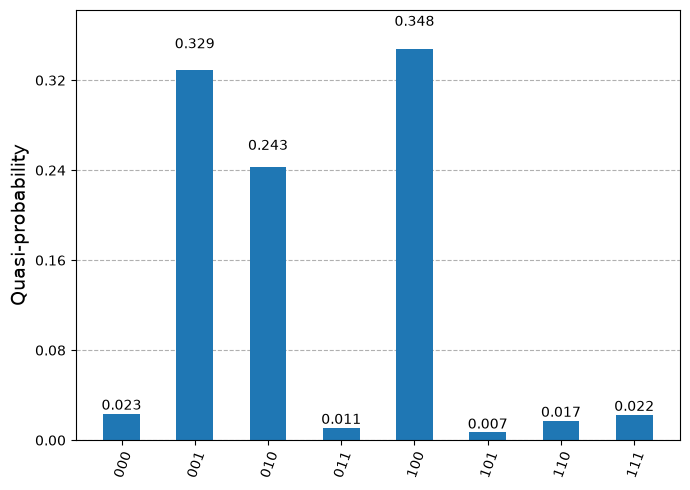

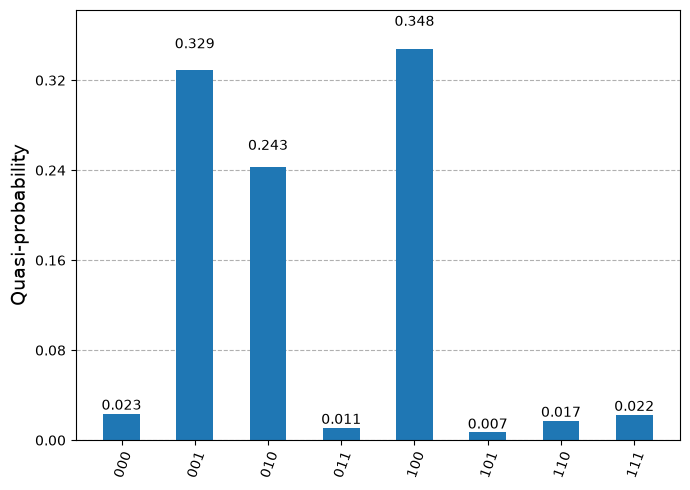

In [20]:
device_result2 = job2.result()

# Get results for the first (and only) PUB
pub_result2 = device_result2[0]

# Get count measurement results
device_counts2 = pub_result2.data.c.get_counts()

print(
    f"Counts for the 'meas' output register: {device_counts2}")

plot_distribution(device_counts2)

In [21]:
mit.cals_from_system(range(circuit2.num_qubits))

mitigate_quasi2 = mit.apply_correction(device_counts2, range(circuit2.num_qubits))
mitigate_probs2 = mitigate_quasi2.nearest_probability_distribution()

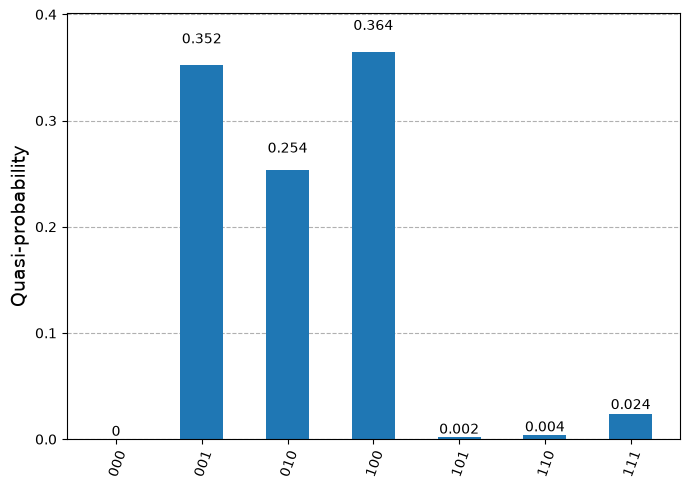

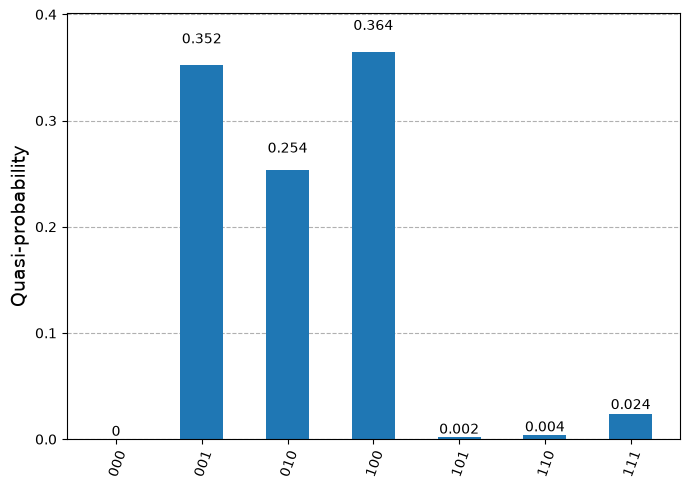

In [22]:
plot_distribution(mitigate_probs2)

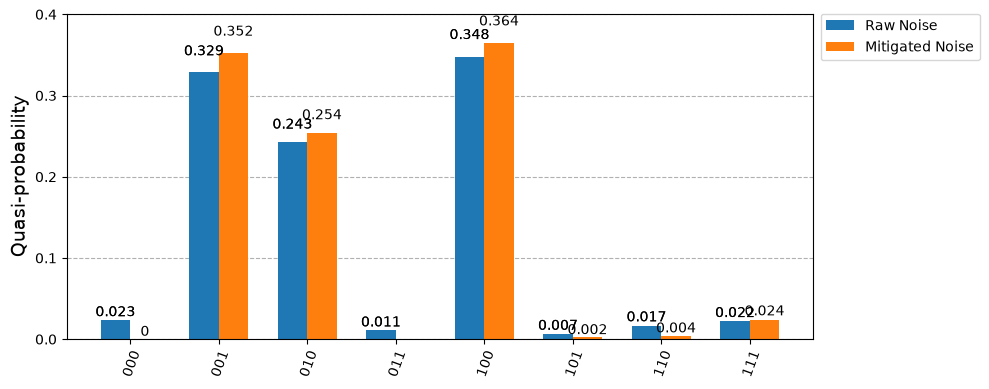

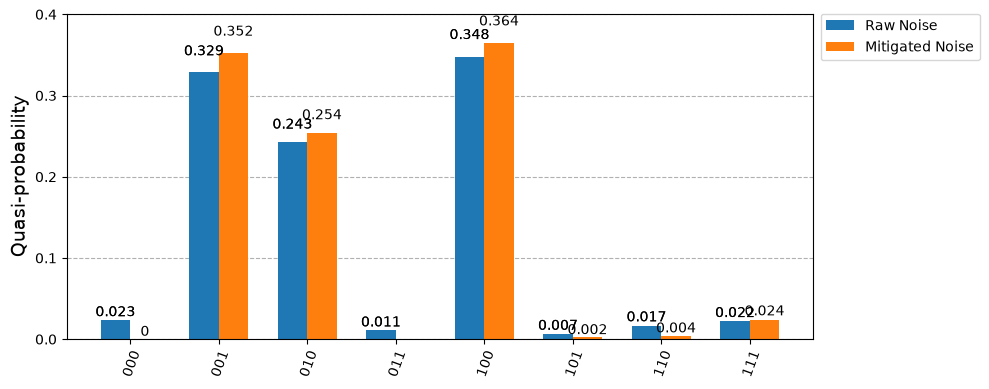

In [23]:
plot_distribution([device_counts2, mitigate_probs2], figsize=(10,4), legend=['Raw Noise', 'Mitigated Noise'])

In [24]:
from qiskit import __version__ as qiskit_version
from qiskit_ibm_runtime import __version__ as runtime_version
from qiskit_aer import __version__ as aer_version
from platform import python_version

print('Qiskit Version:', qiskit_version)
print('IBM RunTime Version:', runtime_version)
print('Qiskit_Aer Version:', aer_version)
print('Python Version:', python_version())
print('2026 ©')

Qiskit Version: 2.5.2
IBM RunTime Version: 0.50.0
Qiskit_Aer Version: 0.17.2
Python Version: 3.12.11
2026 ©
